# Perfiles de salud por pais con pais con PCA y DBSCAN

Datos reales del BGanco Mundial descargados por API

In [1]:
# Importando librerías
import requests                      # para "hablar" con la API por internet
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
# Llamando a la API del Banco Mundial para obtener datos de esperanza de vida en México
URL_BASE = "https://api.worldbank.org/v2"

url = f"{URL_BASE}/country/MEX/indicator/SP.DYN.LE00.IN"
respuesta = requests.get(url, params={"format": "json", "mrnev": 1}, timeout=60)

print("Código de estado:", respuesta.status_code) 

Código de estado: 200


In [3]:
#guardando los datos
datos_json = respuesta.json()
datos_json

[{'page': 1,
  'pages': 1,
  'per_page': 50,
  'total': 1,
  'sourceid': None,
  'lastupdated': '2026-10-08'},
 [{'indicator': {'id': 'SP.DYN.LE00.IN',
    'value': 'Life expectancy at birth, total (years)'},
   'country': {'id': 'MX', 'value': 'Mexico'},
   'countryiso3code': 'MEX',
   'date': '2024',
   'value': 75.264,
   'obs_status': '',
   'decimal': 0}]]

In [4]:
metadatos, registros = datos_json

In [6]:
respuesta = requests.get(f"{URL_BASE}/es/country", params={"format": "json", "per_page": 500}, timeout=60)
metadatos, registros = respuesta.json()

catalogo = pd.json_normalize(registros)        # "aplana" el JSON anidado en columnas
print("Economías en el catálogo:", len(catalogo))
catalogo[["id", "name", "region.id", "region.value", "incomeLevel.value"]].head(8)

Economías en el catálogo: 296


,id,name,region.id,region.value,incomeLevel.value
0,ABW,Aruba,LCN,América Latina y el Caribe,Ingreso alto
1,AFE,,NA,Agregados,Agregados
2,AFG,Afganistán,MEA,"Oriente Medio, Norte de África, Afganistán y P...",Países de ingreso bajo
3,AFR,,NA,Agregados,Agregados
4,AFW,,NA,Agregados,Agregados
5,AGO,Angola,SSF,África al sur del Sahara,Países de ingreso mediano bajo
6,ALB,Albania,ECS,Europa y Asia central,Ingreso mediano alto
7,AND,Andorra,ECS,Europa y Asia central,Ingreso alto


In [7]:
paises = catalogo[catalogo["region.id"] != "NA"]  # excluye países sin región

In [9]:
nombres_region = {
    "EAS": "Asia Oriental y Pacífico",
    "ECS": "Europa y Asia Central",
    "LCN": "América Latina y Caribe",
    "MEA": "Medio Oriente, N. África, Afganistán y Pakistán",
    "NAC": "Norteamérica",
    "SAS": "Asia del Sur",
    "SSF": "África Subsahariana",
}
nombres_ingreso = {"HIC": "Alto", "UMC": "Medio-alto", "LMC": "Medio-bajo", "LIC": "Bajo", "INX": "Sin clasificar"}

# Si aparece un código que no está en el diccionario, usamos el nombre que trae la API
paises["region"] = paises["region.id"].map(nombres_region).fillna(paises["region.value"].str.strip())
paises["ingreso"] = paises["incomeLevel.id"].map(nombres_ingreso).fillna(paises["incomeLevel.value"].str.strip())

paises = paises.rename(columns={"id": "iso3", "name": "pais"})
paises = paises[["iso3", "pais", "region", "ingreso"]]
paises["region"].value_counts()

C:\Users\chels\AppData\Local\Temp\ipykernel_4328\2218399473.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paises["region"] = paises["region.id"].map(nombres_region).fillna(paises["region.value"].str.strip())
C:\Users\chels\AppData\Local\Temp\ipykernel_4328\2218399473.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paises["ingreso"] = paises["incomeLevel.id"].map(nombres_ingreso).fillna(paises["incomeLevel.value"].str.strip())


region
Europa y Asia Central                              58
África Subsahariana                                48
América Latina y Caribe                            42
Asia Oriental y Pacífico                           37
Medio Oriente, N. África, Afganistán y Pakistán    23
Asia del Sur                                        6
Norteamérica                                        3
Name: count, dtype: int64

In [10]:
indicadores = {
    # Resultados en salud
    "SP.DYN.LE00.IN":    "Esperanza de vida",           # años
    "SH.DYN.MORT":       "Mortalidad <5 años",          # muertes por 1,000 nacidos vivos
    "SH.STA.MMRT":       "Mortalidad materna",          # muertes por 100,000 nacidos vivos
    # Recursos y acceso
    "SH.XPD.CHEX.GD.ZS": "Gasto en salud (% PIB)",      # gasto corriente en salud
    "SH.XPD.OOPC.CH.ZS": "Gasto de bolsillo (%)",       # % del gasto en salud que paga el paciente
    "SH.MED.PHYS.ZS":    "Médicos x 1,000 hab.",
    "SH.MED.BEDS.ZS":    "Camas x 1,000 hab.",
    "SH.IMM.IDPT":       "Vacuna DPT (%)",              # % de niños de 12-23 meses vacunados
    # Carga de enfermedad
    "SH.TBS.INCD":       "Tuberculosis x 100,000",      # casos nuevos por año
    "SH.DYN.NCOM.ZS":    "Muerte por ENT 30-70 (%)",    # cardiovascular, cáncer, diabetes, respiratoria
    "SH.STA.DIAB.ZS":    "Diabetes (%)",                # % de adultos de 20 a 79 años
}
print(len(indicadores), "indicadores")

11 indicadores


In [11]:
def descargar_indicador(codigo, fuente=16):
    url = f"{URL_BASE}/country/all/indicator/{codigo}"
    parametros = {"format": "json", "source": fuente, "mrnev": 1, "per_page": 500}
    datos_json = requests.get(url, params=parametros, timeout=60).json()

    # Si la API respondió con un error o sin registros...
    if len(datos_json) < 2 or not datos_json[1]:
        if fuente == 16:
            return descargar_indicador(codigo, fuente=2)    # ...plan B: misma serie en la base WDI
        print(f"⚠️ {codigo}: la API no devolvió datos")
        return pd.DataFrame(columns=["iso3", "anio", "valor"])

    tabla = pd.DataFrame(datos_json[1])[["countryiso3code", "date", "value"]]
    tabla.columns = ["iso3", "anio", "valor"]
    tabla["anio"] = tabla["anio"].astype(int)
    tabla["valor"] = tabla["valor"].astype(float)
    return tabla

In [12]:
tablas = []
for codigo, nombre in indicadores.items():
    tabla = descargar_indicador(codigo)
    if tabla.empty:
        continue
    tabla["indicador"] = nombre
    tablas.append(tabla)
    print(f"✓ {nombre:<26} {tabla['valor'].notna().sum():>4} economías con dato")

largo = pd.concat(tablas, ignore_index=True)
largo = largo[largo["iso3"].isin(paises["iso3"])].copy()    # nos quedamos solo con países reales
largo.head()

✓ Esperanza de vida           260 economías con dato
✓ Mortalidad <5 años          239 economías con dato
✓ Mortalidad materna          237 economías con dato
✓ Gasto en salud (% PIB)      236 economías con dato
✓ Gasto de bolsillo (%)       236 economías con dato
✓ Médicos x 1,000 hab.        251 economías con dato
✓ Camas x 1,000 hab.          244 economías con dato
✓ Vacuna DPT (%)              236 economías con dato
✓ Tuberculosis x 100,000      227 economías con dato
✓ Muerte por ENT 30-70 (%)    228 economías con dato
✓ Diabetes (%)                252 economías con dato


,iso3,anio,valor,indicador
43,AFG,2024,66.289,Esperanza de vida
44,ALB,2024,79.776,Esperanza de vida
45,DZA,2024,76.475,Esperanza de vida
46,ASM,2024,72.992,Esperanza de vida
47,AND,2024,84.188,Esperanza de vida


In [13]:
largo.dropna(subset=["valor"]).groupby("indicador")["anio"].describe()[["min", "50%", "max"]]

,min,50%,max
indicador,,,
"Camas x 1,000 hab.",1970.0,2022.0,2023.0
Diabetes (%),2024.0,2024.0,2024.0
Esperanza de vida,2024.0,2024.0,2024.0
Gasto de bolsillo (%),2021.0,2023.0,2024.0
Gasto en salud (% PIB),2021.0,2023.0,2024.0
Mortalidad <5 años,2024.0,2024.0,2024.0
Mortalidad materna,2023.0,2023.0,2023.0
Muerte por ENT 30-70 (%),2021.0,2021.0,2021.0
"Médicos x 1,000 hab.",1980.0,2022.0,2023.0


In [14]:
ANIO_MINIMO = 2015
largo.loc[largo["anio"] < ANIO_MINIMO, "valor"] = np.nan

# Formato "ancho": una fila por país, una columna por indicador
valores = largo.pivot(index="iso3", columns="indicador", values="valor")
datos = paises.set_index("iso3").join(valores)

columnas_ind = [n for n in indicadores.values() if n in datos.columns]   # en el orden de nuestro diccionario
datos = datos[["pais", "region", "ingreso"] + columnas_ind]

datos.to_csv("datos_salud_banco_mundial.csv")         # respaldo por si la API falla después
datos.head()

,pais,region,ingreso,Esperanza de vida,Mortalidad <5 años,Mortalidad materna,Gasto en salud (% PIB),Gasto de bolsillo (%),"Médicos x 1,000 hab.","Camas x 1,000 hab.",Vacuna DPT (%),"Tuberculosis x 100,000",Muerte por ENT 30-70 (%),Diabetes (%)
iso3,,,,,,,,,,,,,,
ABW,Aruba,América Latina y Caribe,Alto,76.500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.3,NaN,4.6
AFG,Afganistán,"Medio Oriente, N. África, Afganistán y Pakistán",Bajo,66.289,53.0,521.0,14.985763,77.139587,0.317,0.35,59.0,203.0,32.7,11.7
AGO,Angola,África Subsahariana,Medio-bajo,64.805,49.0,183.0,2.546929,32.546677,0.244,0.75,64.0,373.0,24.7,4.9
ALB,Albania,Europa y Asia Central,Medio-alto,79.776,9.2,7.0,7.052403,48.274628,1.879,2.90,97.0,15.0,10.0,10.6
AND,Andorra,Europa y Asia Central,Alto,84.188,2.5,11.0,7.699280,11.145945,5.068,NaN,98.0,4.9,NaN,10.1


In [17]:
#calculando que tan completos vienen loos datos en porcentaje
cobertura = datos[columnas_ind].notna().mean().sort_values()*100

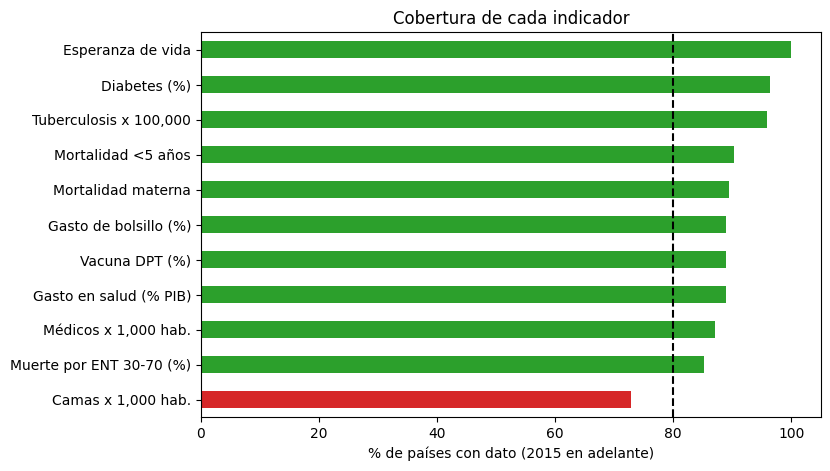

In [18]:
#Descartando variables con menos del 80% de los datos
UMBRAL = 80      # % mínimo de países con dato para conservar un indicador
colores = ["tab:green" if c >= UMBRAL else "tab:red" for c in cobertura]

ax = cobertura.plot(kind="barh", color=colores, figsize=(8, 5))
ax.axvline(UMBRAL, color="black", linestyle="--")
ax.set_xlabel(f"% de países con dato ({ANIO_MINIMO} en adelante)")
ax.set_title("Cobertura de cada indicador")
plt.show()

In [19]:
columnas = [c for c in columnas_ind if cobertura[c] >= UMBRAL]
print("Conservamos:", columnas)
print("Descartamos:", [c for c in columnas_ind if cobertura[c] < UMBRAL])

completos = datos.dropna(subset=columnas)
print(f"\nPaíses con TODOS los indicadores conservados: {len(completos)} de {len(datos)}")

Conservamos: ['Esperanza de vida', 'Mortalidad <5 años', 'Mortalidad materna', 'Gasto en salud (% PIB)', 'Gasto de bolsillo (%)', 'Médicos x 1,000 hab.', 'Vacuna DPT (%)', 'Tuberculosis x 100,000', 'Muerte por ENT 30-70 (%)', 'Diabetes (%)']
Descartamos: ['Camas x 1,000 hab.']

Países con TODOS los indicadores conservados: 180 de 217


In [20]:
# Paises que dejamos fuera
pd.DataFrame({"antes": datos["region"].value_counts(),
              "después": completos["region"].value_counts()})

,antes,después
region,,
Europa y Asia Central,58,48
África Subsahariana,48,47
América Latina y Caribe,42,30
Asia Oriental y Pacífico,37,24
"Medio Oriente, N. África, Afganistán y Pakistán",23,23
Asia del Sur,6,6
Norteamérica,3,2


# Transformando los datos

In [21]:
X = completos[columnas]
sesgo = X.skew().sort_values(ascending=False)
sesgo.round(2)

Mortalidad materna          2.33
Tuberculosis x 100,000      1.93
Mortalidad <5 años          1.53
Diabetes (%)                1.33
Médicos x 1,000 hab.        0.83
Gasto de bolsillo (%)       0.60
Gasto en salud (% PIB)      0.56
Muerte por ENT 30-70 (%)    0.54
Esperanza de vida          -0.38
Vacuna DPT (%)             -1.45
dtype: float64

In [22]:
columnas_log = sesgo[sesgo > 1].index.tolist()        # regla práctica: sesgo > 1 = muy sesgada
print("Aplicamos logaritmo a:", columnas_log)

X_trans = X.copy()
X_trans[columnas_log] = np.log1p(X_trans[columnas_log])   # log(1 + x): funciona aunque haya ceros

Aplicamos logaritmo a: ['Mortalidad materna', 'Tuberculosis x 100,000', 'Mortalidad <5 años', 'Diabetes (%)']


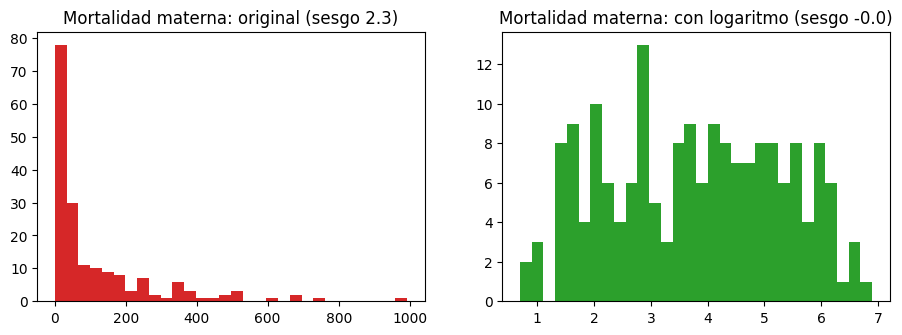

In [23]:
var = sesgo.index[0]          # la variable MÁS sesgada
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
ejes[0].hist(X[var], bins=30, color="tab:red")
ejes[0].set_title(f"{var}: original (sesgo {X[var].skew():.1f})")
ejes[1].hist(X_trans[var], bins=30, color="tab:green")
ejes[1].set_title(f"{var}: con logaritmo (sesgo {X_trans[var].skew():.1f})")
plt.show()

# Escalando con standardscaler

In [24]:
escalador = StandardScaler()
X_esc = escalador.fit_transform(X_trans)

print("Forma:", X_esc.shape, "→ (países, indicadores)")
print("Medias:      ", X_esc.mean(axis=0).round(2))
print("Desv. están.:", X_esc.std(axis=0).round(2))

Forma: (180, 10) → (países, indicadores)
Medias:       [-0. -0.  0. -0.  0. -0.  0. -0.  0.  0.]
Desv. están.: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


# Aplicando PCA a los datos

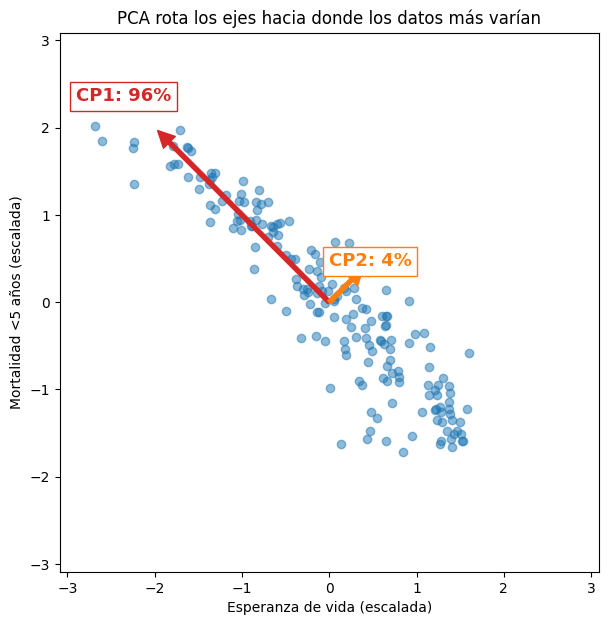

In [25]:
matriz = X_trans.corr().abs().to_numpy(copy=True)
np.fill_diagonal(matriz, 0)
i, j = np.unravel_index(matriz.argmax(), matriz.shape)
var_a, var_b = columnas[i], columnas[j]

dos = X_esc[:, [i, j]]
pca_2 = PCA().fit(dos)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(dos[:, 0], dos[:, 1], alpha=0.5)
for k, color in zip([0, 1], ["tab:red", "tab:orange"]):
    flecha = pca_2.components_[k] * 2 * np.sqrt(pca_2.explained_variance_[k])   # largo = 2 desv. estándar
    ax.annotate("", xy=flecha, xytext=(0, 0), arrowprops=dict(color=color, width=3), annotation_clip=False)
    x, y = flecha * 1.2
    ax.text(x, y, f"CP{k+1}: {pca_2.explained_variance_ratio_[k]:.0%}", color=color, fontsize=13,
            fontweight="bold", ha="center", va="center", bbox=dict(facecolor="white", edgecolor=color))
limite = np.abs(dos).max() * 1.15
ax.set_xlim(-limite, limite)
ax.set_ylim(-limite, limite)
ax.set_xlabel(f"{var_a} (escalada)")
ax.set_ylabel(f"{var_b} (escalada)")
ax.set_aspect("equal")
ax.set_title("PCA rota los ejes hacia donde los datos más varían")
plt.show()

# Aplicando PCA a todos los datos

In [26]:
pca = PCA()
componentes = pca.fit_transform(X_esc)

varianza = pca.explained_variance_ratio_ * 100
acumulada = varianza.cumsum()
for k in range(len(varianza)):
    print(f"CP{k+1}: {varianza[k]:5.1f} %    acumulada: {acumulada[k]:5.1f} %")

CP1:  53.6 %    acumulada:  53.6 %
CP2:  11.4 %    acumulada:  65.1 %
CP3:   8.7 %    acumulada:  73.8 %
CP4:   8.0 %    acumulada:  81.8 %
CP5:   6.1 %    acumulada:  87.8 %
CP6:   4.7 %    acumulada:  92.6 %
CP7:   3.5 %    acumulada:  96.1 %
CP8:   2.5 %    acumulada:  98.6 %
CP9:   0.9 %    acumulada:  99.5 %
CP10:   0.5 %    acumulada: 100.0 %


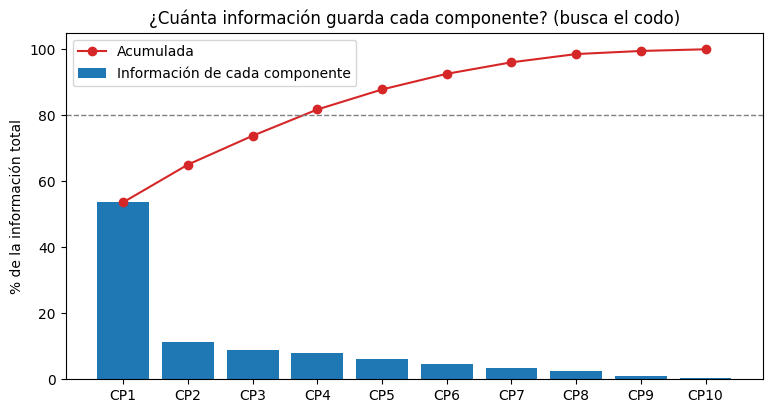

In [27]:
nombres_cp = [f"CP{k+1}" for k in range(len(varianza))]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(nombres_cp, varianza, color="tab:blue", label="Información de cada componente")
ax.plot(nombres_cp, acumulada, color="tab:red", marker="o", label="Acumulada")
ax.axhline(80, color="gray", linestyle="--", linewidth=1)
ax.set_ylabel("% de la información total")
ax.set_title("¿Cuánta información guarda cada componente? (busca el codo)")
ax.legend()
plt.show()

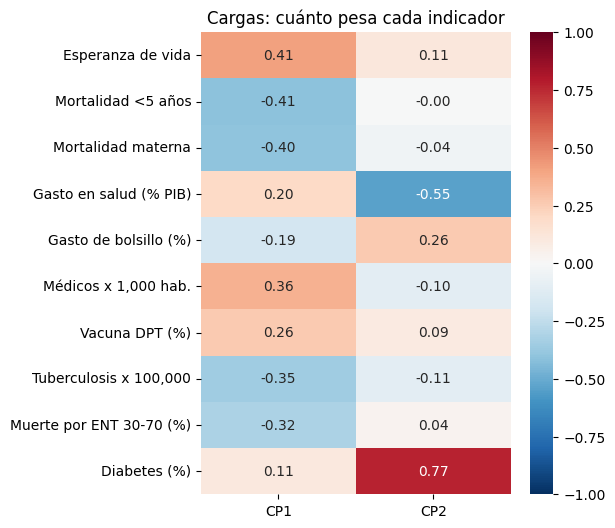

In [28]:
cargas = pd.DataFrame(pca.components_[:2].T, index=columnas, columns=["CP1", "CP2"])

if "Esperanza de vida" in cargas.index and cargas.loc["Esperanza de vida", "CP1"] < 0:
    cargas["CP1"] = -cargas["CP1"]
    componentes[:, 0] = -componentes[:, 0]

plt.figure(figsize=(5, 6))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Cargas: cuánto pesa cada indicador")
plt.show()